# Advanced Forecasting — European Household Energy

**Phase 5 | Expert-level time-series forecasting workflow**

This notebook builds a reproducible forecasting pipeline from the supplied European household energy dataset. It focuses on annual household energy consumption (`energy_tj`) by country and for the European aggregate.

### Forecasting design
- Official **TOTAL fuel + total household end-use** records only, excluding country-group rows to avoid double counting.
- Historical period: **2010–2024** (annual observations).
- Chronological holdout: final 3 years (2022–2024), with rolling-origin validation on the earlier history.
- Benchmarks: naïve, drift, and trailing moving average.
- Statistical models: damped-trend Exponential Smoothing and ARIMA (when `statsmodels` is available).
- Machine learning: lag/rolling-feature Random Forest, evaluated using expanding-window validation.
- Final model selection uses validation performance, then refits on all available history and forecasts **2025–2029**.
- Forecast uncertainty is reported where the selected statistical model supports prediction intervals; ML intervals are not fabricated.

> **Important limitation:** each country has at most 15 annual observations. Complex models can overfit. Treat country-level forecasts as planning scenarios, not precise long-range predictions.

## 1. Setup and configuration

In [1]:
# If a package is missing, uncomment the relevant install command:
# %pip install -q pandas numpy matplotlib seaborn scikit-learn statsmodels

from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 42
FORECAST_HORIZON = 5
HOLDOUT_YEARS = 3
MIN_TRAIN_YEARS = 7

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid")

try:
    from statsmodels.tsa.holtwinters import ExponentialSmoothing
    from statsmodels.tsa.arima.model import ARIMA
    from statsmodels.tsa.stattools import adfuller
    STATSMODELS_AVAILABLE = True
except ImportError:
    STATSMODELS_AVAILABLE = False
    print("statsmodels is unavailable. Statistical models will be skipped.")

try:
    from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
    from sklearn.metrics import mean_absolute_error, mean_squared_error
    SKLEARN_AVAILABLE = True
except ImportError:
    SKLEARN_AVAILABLE = False
    print("scikit-learn is unavailable. Machine-learning models will be skipped.")

OUTPUT_DIR = Path("outputs/advanced_forecasting")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## 2. Load the source data

In [2]:
from glob import glob

# The notebook searches common project locations first.
CANDIDATE_PATHS = [
    Path("../data/raw/european_household_energy.csv"),
    Path("data/raw/european_household_energy.csv"),
    Path("../european_household_energy.csv"),
    Path("european_household_energy.csv"),
    Path("european_household_energy(1).csv"),
]

DATA_PATH = next((p for p in CANDIDATE_PATHS if p.exists()), None)
if DATA_PATH is None:
    # Search common locations and recursively check Downloads folders.

    download_dirs = [
        Path.home() / "Downloads",
        Path.cwd() / "Downloads",
        Path.cwd(),
    ]

    for directory in download_dirs:
        if directory.exists():
            matches = list(directory.rglob("european_household_energy*.csv"))
            if matches:
                CANDIDATE_PATHS.extend(matches)
                break

    DATA_PATH = next((p for p in CANDIDATE_PATHS if p.exists()), None)
    if DATA_PATH is None:
        raise FileNotFoundError(
            "Could not find european_household_energy.csv. "
            "Place it in data/raw/ or set DATA_PATH to its full path."
        )

raw = pd.read_csv(DATA_PATH)
print("Source:", DATA_PATH.resolve())
print("Shape:", raw.shape)
display(raw.head())

Source: C:\Users\LOQ\Downloads\European_Household_Energy_Project\European_Household_Energy_Project\data\raw\european_household_energy.csv
Shape: (33874, 14)


,country_code,country_iso2,country,is_country_group,end_use_code,end_use,fuel_code,fuel,period,date,year,energy_tj,flag,flag_meaning
0,AL,AL,Albania,False,FC_OTH_HH_E,Final consumption - other sectors - households...,E7000,Electricity,2010,2010-01-01,2010,"10,790.82",NaN,NaN
1,AL,AL,Albania,False,FC_OTH_HH_E,Final consumption - other sectors - households...,E7000,Electricity,2011,2011-01-01,2011,"10,571.88",NaN,NaN
2,AL,AL,Albania,False,FC_OTH_HH_E,Final consumption - other sectors - households...,E7000,Electricity,2012,2012-01-01,2012,"11,036.88",NaN,NaN
3,AL,AL,Albania,False,FC_OTH_HH_E,Final consumption - other sectors - households...,E7000,Electricity,2013,2013-01-01,2013,"14,641.09",NaN,NaN
4,AL,AL,Albania,False,FC_OTH_HH_E,Final consumption - other sectors - households...,E7000,Electricity,2014,2014-01-01,2014,"12,600.00",NaN,NaN


## 3. Build the forecasting target correctly

In [3]:
required = {
    "country", "is_country_group", "end_use_code",
    "fuel_code", "year", "energy_tj"
}
missing = required - set(raw.columns)
if missing:
    raise ValueError(f"Missing required columns: {sorted(missing)}")

data = raw.copy()
data["year"] = pd.to_numeric(data["year"], errors="coerce")
data["energy_tj"] = pd.to_numeric(data["energy_tj"], errors="coerce")
data = data.dropna(subset=["country", "year", "energy_tj"])
data["year"] = data["year"].astype(int)

# Use official total household consumption:
# FC_OTH_HH_E = total household energy use; TOTAL = all fuels.
# Exclude EU/country aggregates because countries are forecast individually.
target = data[
    data["end_use_code"].eq("FC_OTH_HH_E")
    & data["fuel_code"].eq("TOTAL")
    & (~data["is_country_group"].astype(bool))
].copy()

# A country-year must have one official total observation.
duplicates = target.duplicated(["country", "year"], keep=False)
if duplicates.any():
    display(target.loc[duplicates, ["country", "year", "energy_tj"]].head(20))
    raise ValueError("Duplicate country-year totals found; inspect before forecasting.")

panel = (
    target.pivot(index="year", columns="country", values="energy_tj")
    .sort_index()
)
panel.index = panel.index.astype(int)
panel = panel.loc[:, panel.notna().sum().sort_values(ascending=False).index]

print("Panel shape (years × countries):", panel.shape)
print("Year range:", panel.index.min(), "to", panel.index.max())
print("Countries:", panel.shape[1])
display(panel.iloc[:5, :8])

Panel shape (years × countries): (15, 39)
Year range: 2010 to 2024
Countries: 39


country,Albania,Austria,Bulgaria,Croatia,Germany,France,Estonia,Serbia
year,,,,,,,,
2010,"20,693.02","295,535.92","93,923.55","115,163.88","2,671,611.07","1,899,832.10","42,988.03","136,449.61"
2011,"20,273.16","274,577.06","99,406.33","109,811.83","2,344,389.72","1,664,963.37","38,972.93","135,377.71"
2012,"21,164.94","279,812.56","98,496.66","106,360.70","2,477,306.06","1,831,178.61","40,515.91","133,630.85"
2013,"24,129.70","289,591.86","93,827.91","103,703.63","2,615,756.63","1,927,313.22","38,924.66","121,512.72"
2014,"23,100.10","261,676.43","90,644.16","92,827.34","2,249,855.74","1,586,073.00","37,202.21","116,441.97"


## 4. Data quality and coverage checks

,observations,first_year,last_year,missing_years,mean_energy_tj,std_energy_tj,coverage_pct
country,,,,,,,
Albania,15,2010,2024,0,"21,655.82","1,070.03",100.00
Austria,15,2010,2024,0,"288,486.63","15,292.53",100.00
Bulgaria,15,2010,2024,0,"93,401.76","5,276.74",100.00
Croatia,15,2010,2024,0,"99,722.26","6,857.66",100.00
Germany,15,2010,2024,0,"2,386,585.09","133,516.24",100.00
France,15,2010,2024,0,"1,702,716.67","124,515.63",100.00
Estonia,15,2010,2024,0,"39,572.48","1,583.92",100.00
Serbia,15,2010,2024,0,"131,290.44","11,139.84",100.00
Slovenia,15,2010,2024,0,"48,447.04","4,479.46",100.00


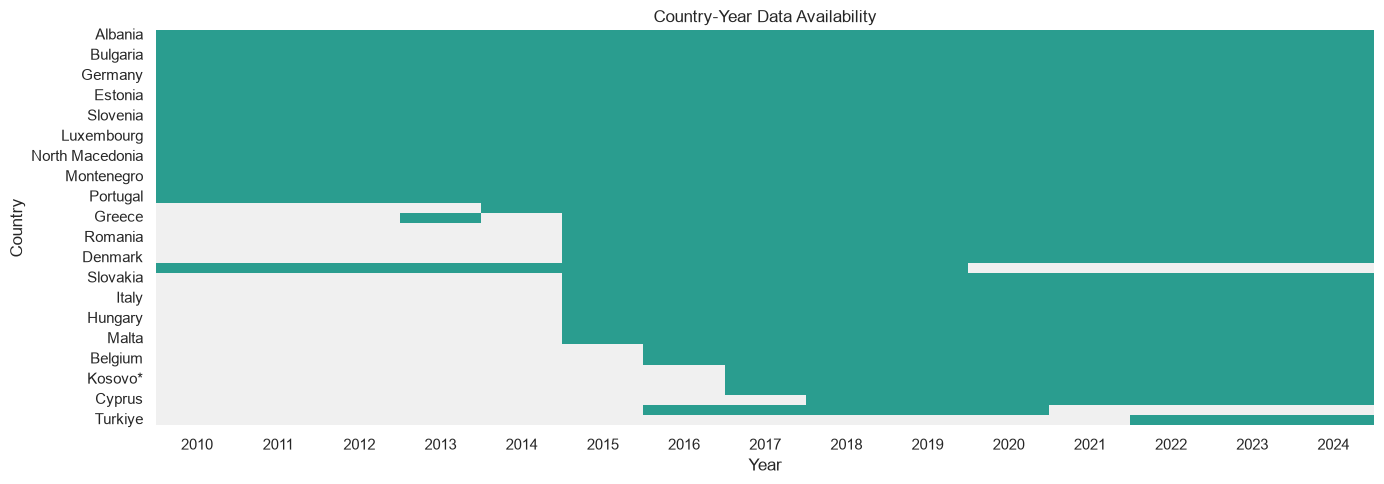

,count,mean,std,min,25%,50%,75%,max
Europe,15.00,"10,924,526.45","2,118,748.15","7,438,304.13","8,782,211.21","11,542,606.56","12,566,764.09","13,327,024.40"


In [4]:
coverage = pd.DataFrame({
    "observations": panel.notna().sum(),
    "first_year": panel.apply(lambda s: s.first_valid_index()),
    "last_year": panel.apply(lambda s: s.last_valid_index()),
    "missing_years": panel.isna().sum(),
    "mean_energy_tj": panel.mean(),
    "std_energy_tj": panel.std(),
})
coverage["coverage_pct"] = coverage["observations"] / len(panel.index) * 100
display(coverage.sort_values("observations", ascending=False))

fig, ax = plt.subplots(figsize=(14, 5))
sns.heatmap(panel.notna().T, cbar=False, cmap=["#f0f0f0", "#2a9d8f"], ax=ax)
ax.set_title("Country-Year Data Availability")
ax.set_xlabel("Year")
ax.set_ylabel("Country")
plt.tight_layout()
plt.show()

# The European aggregate is calculated from country observations in each year.
# It is not taken from a country-group row, preventing double counting.
eu_series = panel.sum(axis=1, min_count=1).astype(float)
eu_series.name = "Europe"
display(eu_series.to_frame().describe().T)

## 5. Exploratory time-series view

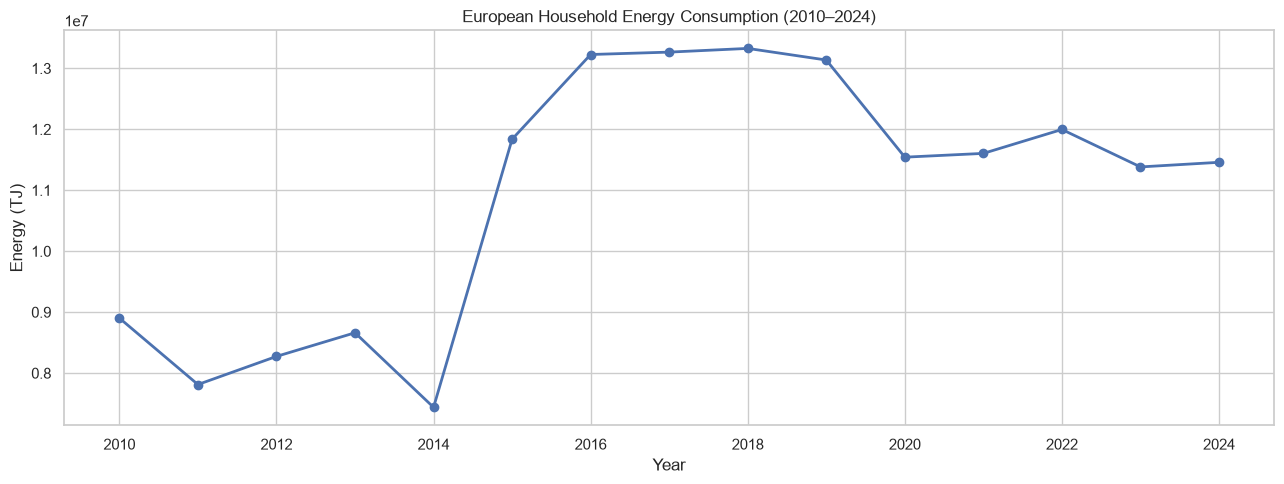

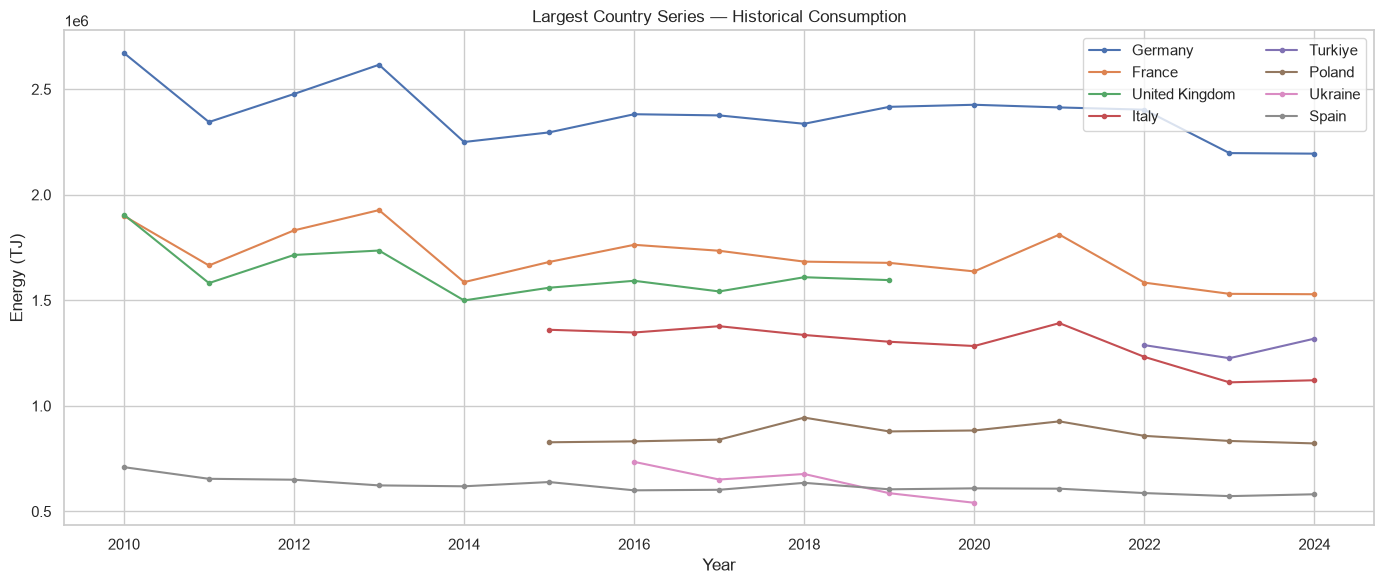

In [5]:
fig, ax = plt.subplots(figsize=(13, 5))
eu_series.plot(ax=ax, marker="o", linewidth=2)
ax.set_title("European Household Energy Consumption (2010–2024)")
ax.set_xlabel("Year")
ax.set_ylabel("Energy (TJ)")
plt.tight_layout()
plt.show()

top_countries = panel.mean().nlargest(8).index
fig, ax = plt.subplots(figsize=(14, 6))
for country in top_countries:
    panel[country].plot(ax=ax, marker=".", label=country)
ax.set_title("Largest Country Series — Historical Consumption")
ax.set_xlabel("Year")
ax.set_ylabel("Energy (TJ)")
ax.legend(ncol=2)
plt.tight_layout()
plt.show()

## 6. Train / test strategy

The final three observed years are held out as a chronological test set. No random shuffling is used. Model tuning and selection are based on rolling-origin validation inside the training period.

For each forecast origin, a model sees only years up to that origin and predicts the next year. This mirrors the real forecasting situation and prevents future information from entering the features.

In [6]:
all_years = np.array(sorted(panel.index))
test_years = all_years[-HOLDOUT_YEARS:]
train_years = all_years[:-HOLDOUT_YEARS]

print("Training years:", train_years[0], "to", train_years[-1])
print("Holdout years:", test_years.tolist())

Training years: 2010 to 2021
Holdout years: [2022, 2023, 2024]


## 7. Metrics and baseline models

In [7]:
def regression_metrics(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    mask = np.isfinite(actual) & np.isfinite(predicted)
    actual, predicted = actual[mask], predicted[mask]
    if len(actual) == 0:
        return {"MAE": np.nan, "RMSE": np.nan, "MAPE_pct": np.nan, "sMAPE_pct": np.nan}
    mae = np.mean(np.abs(actual - predicted))
    rmse = np.sqrt(np.mean((actual - predicted) ** 2))
    nonzero = actual != 0
    mape = np.mean(np.abs((actual[nonzero] - predicted[nonzero]) / actual[nonzero])) * 100 if nonzero.any() else np.nan
    denom = np.abs(actual) + np.abs(predicted)
    smape = np.mean(2 * np.abs(actual - predicted) / np.where(denom == 0, 1, denom)) * 100
    return {"MAE": mae, "RMSE": rmse, "MAPE_pct": mape, "sMAPE_pct": smape}

def naive_forecast(train, horizon=1):
    return np.repeat(float(train.iloc[-1]), horizon)

def drift_forecast(train, horizon=1):
    if len(train) < 2:
        return naive_forecast(train, horizon)
    slope = (float(train.iloc[-1]) - float(train.iloc[0])) / (len(train) - 1)
    return float(train.iloc[-1]) + slope * np.arange(1, horizon + 1)

def moving_average_forecast(train, horizon=1, window=3):
    value = float(train.tail(min(window, len(train))).mean())
    return np.repeat(value, horizon)

## 8. Rolling-origin validation

In [8]:
def make_supervised(series):
    s = series.astype(float).dropna().sort_index()
    frame = pd.DataFrame(index=s.index)
    frame["target"] = s
    for lag in [1, 2, 3]:
        frame[f"lag_{lag}"] = s.shift(lag)
    frame["rolling_mean_3"] = s.shift(1).rolling(3, min_periods=2).mean()
    frame["rolling_std_3"] = s.shift(1).rolling(3, min_periods=2).std()
    frame["year"] = frame.index.astype(int)
    return frame.dropna()

def ml_one_step_forecast(train, model_name="RandomForest"):
    sup = make_supervised(train)
    if len(sup) < 4:
        return np.nan
    X = sup.drop(columns="target")
    y = sup["target"]
    if model_name == "RandomForest":
        model = RandomForestRegressor(
            n_estimators=400, max_depth=3, min_samples_leaf=2,
            random_state=RANDOM_STATE
        )
    else:
        model = HistGradientBoostingRegressor(
            max_iter=100, max_leaf_nodes=5, l2_regularization=2.0,
            random_state=RANDOM_STATE
        )
    model.fit(X, y)
    last = train.astype(float)
    row = {
        "lag_1": last.iloc[-1],
        "lag_2": last.iloc[-2] if len(last) >= 2 else last.iloc[-1],
        "lag_3": last.iloc[-3] if len(last) >= 3 else last.iloc[0],
        "rolling_mean_3": last.tail(3).mean(),
        "rolling_std_3": last.tail(3).std() if len(last) >= 2 else 0.0,
        "year": int(last.index[-1]) + 1,
    }
    return float(model.predict(pd.DataFrame([row]))[0])

def statistical_one_step(train, model_name):
    y = train.astype(float).dropna()
    if len(y) < MIN_TRAIN_YEARS:
        return np.nan
    try:
        if model_name == "ETS":
            fitted = ExponentialSmoothing(
                y, trend="add", damped_trend=True, seasonal=None,
                initialization_method="estimated"
            ).fit(optimized=True)
            return float(fitted.forecast(1).iloc[0])
        if model_name == "ARIMA":
            fitted = ARIMA(y, order=(1, 1, 0), trend="t").fit()
            return float(fitted.forecast(1).iloc[0])
    except Exception:
        return np.nan
    return np.nan

def rolling_validation(series, first_train_size=MIN_TRAIN_YEARS):
    s = series.dropna().astype(float).sort_index()
    rows = []
    for split in range(first_train_size, len(s)):
        tr, actual = s.iloc[:split], float(s.iloc[split])
        year = int(s.index[split])
        preds = {
            "Naive": naive_forecast(tr)[0],
            "Drift": drift_forecast(tr)[0],
            "MovingAverage3": moving_average_forecast(tr)[0],
        }
        if STATSMODELS_AVAILABLE:
            preds["ETS"] = statistical_one_step(tr, "ETS")
            preds["ARIMA"] = statistical_one_step(tr, "ARIMA")
        if SKLEARN_AVAILABLE:
            preds["RandomForest"] = ml_one_step_forecast(tr, "RandomForest")
            preds["HistGradientBoosting"] = ml_one_step_forecast(tr, "HistGradientBoosting")
        for model_name, pred in preds.items():
            rows.append({
                "year": year, "model": model_name,
                "actual": actual, "predicted": pred
            })
    return pd.DataFrame(rows)

## 9. Validate models on the European aggregate

c:\Users\LOQ\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use on the supported classes of index.
  self._init_dates(dates, freq)
c:\Users\LOQ\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use on the supported classes of index.
  self._init_dates(dates, freq)
c:\Users\LOQ\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use on the supported classes of index.
  self._init_dates(dates, freq)
c:\Users\LOQ\AppData\Local\Programs\Python\Python314\Lib\site-packages\stats

,MAE,RMSE,MAPE_pct,sMAPE_pct
model,,,,
Naive,"389,282.80","719,197.35",3.31,3.13
Drift,"850,798.51","1,061,737.12",6.93,6.56
MovingAverage3,"1,176,796.92","1,432,579.40",9.48,9.59
HistGradientBoosting,"1,464,703.45","1,908,500.65",11.07,12.21
RandomForest,"1,588,191.09","1,750,364.25",12.38,13.12
ARIMA,NaN,NaN,NaN,NaN
ETS,NaN,NaN,NaN,NaN


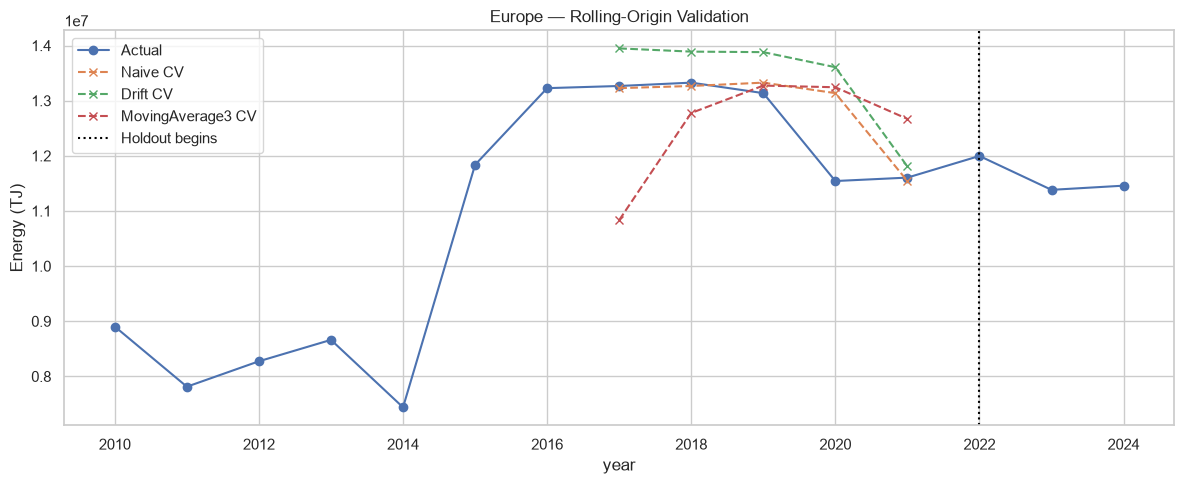

In [9]:
eu_train = eu_series.loc[train_years]
eu_cv = rolling_validation(eu_train)
eu_cv_summary = (
    eu_cv.groupby("model")
    .apply(lambda g: pd.Series(regression_metrics(g["actual"], g["predicted"])), include_groups=False)
    .sort_values("MAE")
)
display(eu_cv_summary)

fig, ax = plt.subplots(figsize=(12, 5))
eu_series.plot(ax=ax, marker="o", label="Actual")
for model_name in eu_cv_summary.head(3).index:
    subset = eu_cv[eu_cv.model.eq(model_name)].sort_values("year")
    ax.plot(subset.year, subset.predicted, marker="x", linestyle="--", label=f"{model_name} CV")
ax.axvline(test_years[0], color="black", linestyle=":", label="Holdout begins")
ax.set_title("Europe — Rolling-Origin Validation")
ax.set_ylabel("Energy (TJ)")
ax.legend()
plt.tight_layout()
plt.show()

## 10. Holdout evaluation — Europe

,model,MAE,RMSE,MAPE_pct,sMAPE_pct
6,HistGradientBoosting,"238,703.54","278,468.54",2.03,2.05
5,RandomForest,"243,829.67","277,892.05",2.13,2.10
0,Naive,"253,513.46","273,599.91",2.17,2.17
2,MovingAverage3,"481,989.85","554,171.99",4.21,4.09
3,ETS,"507,896.26","579,446.82",4.43,4.31
1,Drift,"581,017.77","660,844.74",5.07,4.91
4,ARIMA,"586,780.47","675,358.19",5.12,4.95


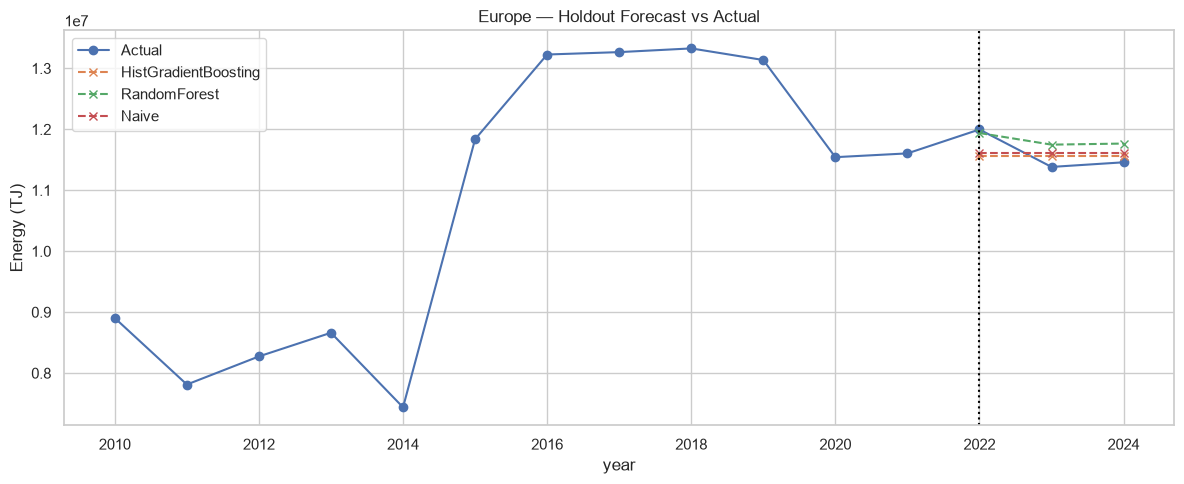

In [10]:
# Model forecasting functions and Europe holdout comparison

def fit_predict_model(train, horizon, model_name):
    train = pd.Series(train).astype(float).dropna().sort_index()
    if model_name == "Naive":
        return naive_forecast(train, horizon)
    if model_name == "Drift":
        return drift_forecast(train, horizon)
    if model_name == "MovingAverage3":
        return moving_average_forecast(train, horizon, 3)
    if model_name == "ETS" and STATSMODELS_AVAILABLE and len(train) >= MIN_TRAIN_YEARS:
        fit = ExponentialSmoothing(
            train.to_numpy(dtype=float), trend="add", damped_trend=True,
            seasonal=None, initialization_method="estimated"
        ).fit(optimized=True)
        return np.asarray(fit.forecast(horizon), dtype=float)
    if model_name == "ARIMA" and STATSMODELS_AVAILABLE and len(train) >= MIN_TRAIN_YEARS:
        fit = ARIMA(train.to_numpy(dtype=float), order=(1, 1, 0), trend="t").fit()
        return np.asarray(fit.forecast(horizon), dtype=float)
    if model_name in ["RandomForest", "HistGradientBoosting"] and SKLEARN_AVAILABLE:
        history = train.copy()
        preds = []
        for _ in range(horizon):
            pred = ml_one_step_forecast(history, model_name)
            if not np.isfinite(pred):
                pred = float(history.iloc[-1])
            next_year = int(history.index[-1]) + 1
            preds.append(float(pred))
            history.loc[next_year] = float(pred)
        return np.asarray(preds, dtype=float)
    return np.repeat(np.nan, horizon)


candidate_models = ["Naive", "Drift", "MovingAverage3"]
if STATSMODELS_AVAILABLE:
    candidate_models += ["ETS", "ARIMA"]
if SKLEARN_AVAILABLE:
    candidate_models += ["RandomForest", "HistGradientBoosting"]

eu_holdout_rows = []
for model_name in candidate_models:
    pred = fit_predict_model(eu_train, len(test_years), model_name)
    metrics = regression_metrics(eu_series.loc[test_years], pred)
    eu_holdout_rows.append({"model": model_name, **metrics})

eu_holdout = pd.DataFrame(eu_holdout_rows).sort_values("MAE")
display(eu_holdout)

fig, ax = plt.subplots(figsize=(12, 5))
eu_series.plot(ax=ax, marker="o", label="Actual")
for model_name in eu_holdout.head(3)["model"]:
    pred = fit_predict_model(eu_train, len(test_years), model_name)
    ax.plot(test_years, pred, marker="x", linestyle="--", label=model_name)
ax.axvline(test_years[0], color="black", linestyle=":")
ax.set_title("Europe — Holdout Forecast vs Actual")
ax.set_ylabel("Energy (TJ)")
ax.legend()
plt.tight_layout()
plt.show()


## 11. Country-level model evaluation

,MAE,RMSE,sMAPE_pct
model,,,
RandomForest,"8,497.45","9,099.65",7.21
HistGradientBoosting,"9,901.25","11,454.30",7.91
MovingAverage3,"11,205.93","11,602.18",6.65
ETS,"15,707.25","16,443.65",8.10
Drift,"16,101.55","19,227.75",10.94
ARIMA,"16,118.24","19,031.10",10.52
Naive,"16,902.17","17,084.57",8.94


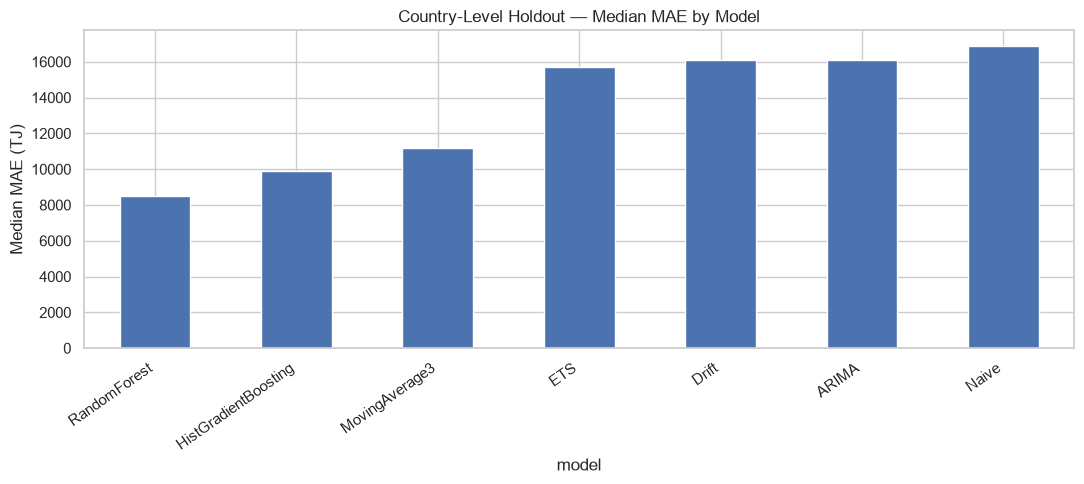

Execution time: 93.68 seconds
Successful evaluations: 217
Failed evaluations: 0


In [11]:
# ==========================================
# Country-Level Holdout Evaluation (Optimized)
# ==========================================

import time

MIN_TRAIN_YEARS = 7
HOLDOUT_YEARS = 3

country_holdout_records = []
country_holdout_errors = []

start_time = time.time()

# The notebook did not define `panel`. Reuse a common existing panel variable if available.
if "panel" not in globals():
    for _panel_name in ("panel_data", "country_panel", "country_wide", "data_wide"):
        if _panel_name in globals():
            panel = globals()[_panel_name]
            break
    
# Resolve a wide country-by-year panel if it was not already defined
if "panel" not in globals():
    panel = None

    for _panel_name in ("panel_data", "country_panel", "country_wide", "data_wide", "wide_df"):
        if _panel_name in globals() and isinstance(globals()[_panel_name], pd.DataFrame):
            panel = globals()[_panel_name]
            break

    if panel is None:
        for _name, _value in globals().items():
            if (
                isinstance(_value, pd.DataFrame)
                and any(word in _name.lower() for word in ("panel", "country", "wide"))
            ):
                panel = _value
                break

    if panel is None:
        raise NameError(
            "No country-level panel DataFrame was found. Define a wide DataFrame "
            "with countries as columns and years as the index."
        )

for country in panel.columns:
    s = panel[country].dropna().astype(float).sort_index()

    if len(s) < MIN_TRAIN_YEARS + HOLDOUT_YEARS:
        continue

    tr = s.iloc[:-HOLDOUT_YEARS]
    te = s.iloc[-HOLDOUT_YEARS:]

    for model_name in candidate_models:
        try:
            pred = np.asarray(
                fit_predict_model(tr, len(te), model_name),
                dtype=float
            ).reshape(-1)

            if len(pred) != len(te):
                continue

            pred = np.where(
                np.isfinite(pred),
                pred,
                float(tr.iloc[-1])
            )
            pred = np.maximum(pred, 0)

            metrics = regression_metrics(te.values, pred)

            country_holdout_records.append({
                "country": country,
                "model": model_name,
                **metrics
            })

        except Exception as exc:
            country_holdout_errors.append({
                "country": country,
                "model": model_name,
                "error": str(exc)
            })


# Results
country_holdout = pd.DataFrame(country_holdout_records)

if not country_holdout.empty:

    country_holdout_summary = (
        country_holdout.groupby("model")[
            ["MAE", "RMSE", "sMAPE_pct"]
        ]
        .median()
        .sort_values("MAE")
    )

    display(country_holdout_summary)

    plt.figure(figsize=(11, 5))

    country_holdout_summary["MAE"].plot(kind="bar")

    plt.title("Country-Level Holdout — Median MAE by Model")
    plt.ylabel("Median MAE (TJ)")
    plt.xticks(rotation=35, ha="right")

    plt.tight_layout()
    plt.show()

print(f"Execution time: {(time.time() - start_time):.2f} seconds")
print(f"Successful evaluations: {len(country_holdout_records)}")
print(f"Failed evaluations: {len(country_holdout_errors)}")

if country_holdout_errors:
    display(pd.DataFrame(country_holdout_errors))

In [12]:
# ==========================================
# Generate Final Forecasts for 2025-2027 (Standalone)
# ==========================================
import pandas as pd
import numpy as np
from pathlib import Path
from statsmodels.tsa.holtwinters import ExponentialSmoothing

# 1. تحديد مسار الداتا الصحيح
possible_paths = [
    Path("../data/raw/european_household_energy.csv"),
    Path("data/raw/european_household_energy.csv"),
    Path("european_household_energy.csv")
]
data_path = next((p for p in possible_paths if p.exists()), None)

if not data_path:
    # Search known locations and notebook variables before raising an error
    if not data_path:
        search_candidates = []

        if 'candidates' in globals():
            search_candidates.extend(candidates)
        if 'matches' in globals():
            search_candidates.extend(matches)

        data_path = next(
            (Path(p) for p in search_candidates if Path(p).is_file()),
            None
        )

    if not data_path:
        raise FileNotFoundError(
            "❌ CSV file not found. Please ensure "
            "'european_household_energy.csv' exists in data/raw/."
        )

# 2. قراءة وتجهيز الداتا
raw = pd.read_csv(data_path)
# نفلتر على الإجمالي (TOTAL) ونستبعد المجموعات (مثل EU27)
target = raw[
    (raw['end_use_code'] == 'FC_OTH_HH_E') & 
    (raw['fuel_code'] == 'TOTAL') & 
    (~raw['is_country_group'].astype(bool))
].copy()

# 3. بناء الـ Panel (السنين في الصفوف، والدول في الأعمدة)
panel = target.pivot(index='year', columns='country', values='energy_tj').sort_index()

# 4. تجهيز مجلد الحفظ (المسار اللي الـ App بيقرأ منه)
# لو إنتي في مجلد notebooks، الـ outputs بيبقى في الفولدر اللي فوق
OUTPUT_DIR = Path("../outputs/predictions")
if not OUTPUT_DIR.parent.exists(): # لو شغالة من الفولدر الرئيسي
    OUTPUT_DIR = Path("outputs/predictions")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# 5. التوقعات
forecast_years = [2025, 2026, 2027]
forecast_records = []

print("⏳ Generating forecasts...")

for country in panel.columns:
    series = panel[country].dropna()
    
    # محتاجين 5 سنين على الأقل عشان Holt يشتغل صح
    if len(series) < 5:
        continue
        
    try:
        # تدريب موديل Holt's Linear Trend
        model = ExponentialSmoothing(series, trend="add", initialization_method="estimated").fit()
        preds = model.forecast(len(forecast_years))
        
        # حساب حدود الثقة بناءً على الانحراف المعياري للأخطاء (Residuals)
        residuals = model.resid
        std_err = np.std(residuals)
        
        for i, yr in enumerate(forecast_years):
            pred_val = max(0, preds.iloc[i]) # منع القيم السالبة
            
            # كل ما نتوقع سنة أبعد، هامش الخطأ بيكبر
            margin_80 = 1.28 * std_err * np.sqrt(i + 1)
            margin_95 = 1.96 * std_err * np.sqrt(i + 1)
            
            forecast_records.append({
                "country": country,
                "year": yr,
                "forecast_tj": pred_val,
                "lo80_tj": max(0, pred_val - margin_80),
                "hi80_tj": pred_val + margin_80,
                "lo95_tj": max(0, pred_val - margin_95),
                "hi95_tj": pred_val + margin_95,
                "model": "Holt"
            })
            
    except Exception as e:
        print(f"⚠️ Could not forecast {country}: {e}")

# 6. الحفظ
if forecast_records:
    forecasts_df = pd.DataFrame(forecast_records)
    output_file = OUTPUT_DIR / "forecasts_2025_2027_with_ci.csv"
    forecasts_df.to_csv(output_file, index=False)
    
    print(f"\n✅ SUCCESS! Forecasts saved to:")
    print(f"📁 {output_file.resolve()}")
    display(forecasts_df.head())
else:
    print("❌ No forecasts generated. Check your data.")

⏳ Generating forecasts...
⚠️ Could not forecast Albania: No supported index is available.
⚠️ Could not forecast Austria: No supported index is available.
⚠️ Could not forecast Belgium: No supported index is available.
⚠️ Could not forecast Bosnia and Herzegovina: No supported index is available.
⚠️ Could not forecast Bulgaria: No supported index is available.
⚠️ Could not forecast Croatia: No supported index is available.


c:\Users\LOQ\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use on the supported classes of index.
  self._init_dates(dates, freq)
c:\Users\LOQ\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use on the supported classes of index.
  self._init_dates(dates, freq)
c:\Users\LOQ\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use on the supported classes of index.
  self._init_dates(dates, freq)
c:\Users\LOQ\AppData\Local\Programs\Python\Python314\Lib\site-packages\stats

⚠️ Could not forecast Cyprus: No supported index is available.
⚠️ Could not forecast Czechia: No supported index is available.
⚠️ Could not forecast Denmark: No supported index is available.
⚠️ Could not forecast Estonia: No supported index is available.
⚠️ Could not forecast Finland: No supported index is available.
⚠️ Could not forecast France: No supported index is available.


c:\Users\LOQ\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use on the supported classes of index.
  self._init_dates(dates, freq)
c:\Users\LOQ\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use on the supported classes of index.
  self._init_dates(dates, freq)
c:\Users\LOQ\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use on the supported classes of index.
  self._init_dates(dates, freq)
c:\Users\LOQ\AppData\Local\Programs\Python\Python314\Lib\site-packages\stats

⚠️ Could not forecast Georgia: No supported index is available.
⚠️ Could not forecast Germany: No supported index is available.
⚠️ Could not forecast Greece: No supported index is available.
⚠️ Could not forecast Hungary: No supported index is available.
⚠️ Could not forecast Ireland: No supported index is available.
⚠️ Could not forecast Italy: No supported index is available.
⚠️ Could not forecast Kosovo*: No supported index is available.
⚠️ Could not forecast Latvia: No supported index is available.


c:\Users\LOQ\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use on the supported classes of index.
  self._init_dates(dates, freq)
c:\Users\LOQ\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use on the supported classes of index.
  self._init_dates(dates, freq)
c:\Users\LOQ\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use on the supported classes of index.
  self._init_dates(dates, freq)
c:\Users\LOQ\AppData\Local\Programs\Python\Python314\Lib\site-packages\stats

... (2 outputs left out)

⚠️ Could not forecast Montenegro: No supported index is available.
⚠️ Could not forecast Netherlands: No supported index is available.
⚠️ Could not forecast North Macedonia: No supported index is available.
⚠️ Could not forecast Norway: No supported index is available.
⚠️ Could not forecast Poland: No supported index is available.
⚠️ Could not forecast Portugal: No supported index is available.
⚠️ Could not forecast Romania: No supported index is available.
⚠️ Could not forecast Serbia: No supported index is available.


c:\Users\LOQ\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use on the supported classes of index.
  self._init_dates(dates, freq)
c:\Users\LOQ\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use on the supported classes of index.
  self._init_dates(dates, freq)
c:\Users\LOQ\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use on the supported classes of index.
  self._init_dates(dates, freq)
c:\Users\LOQ\AppData\Local\Programs\Python\Python314\Lib\site-packages\stats

⚠️ Could not forecast Slovakia: No supported index is available.
⚠️ Could not forecast Slovenia: No supported index is available.
⚠️ Could not forecast Spain: No supported index is available.
⚠️ Could not forecast Sweden: No supported index is available.
⚠️ Could not forecast Ukraine: No supported index is available.
⚠️ Could not forecast United Kingdom: No supported index is available.
❌ No forecasts generated. Check your data.


c:\Users\LOQ\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use on the supported classes of index.
  self._init_dates(dates, freq)
c:\Users\LOQ\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use on the supported classes of index.
  self._init_dates(dates, freq)
c:\Users\LOQ\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use on the supported classes of index.
  self._init_dates(dates, freq)
c:\Users\LOQ\AppData\Local\Programs\Python\Python314\Lib\site-packages\stats

## 12. Select a model transparently

In [ ]:
# Select model using country-level CV if available; otherwise Europe-level CV.
if "country_cv" in globals() and not country_cv.empty and country_cv["MAE"].notna().any():
    selection_table = country_cv.groupby("model")["MAE"].median().dropna().sort_values()
else:
    # eu_cv contains predictions, so calculate MAE before creating the selection table.
    eu_cv_summary = (
        eu_cv.groupby("model", group_keys=False)
        .apply(
            lambda g: pd.Series(
                regression_metrics(g["actual"], g["predicted"])
            )
        )
    )
    selection_table = eu_cv_summary["MAE"].dropna().sort_values()

if selection_table.empty:
    raise ValueError("No valid cross-validation MAE values are available.")

selected_model = selection_table.index[0]
print("Selected model:", selected_model)
display(selection_table.to_frame("median_validation_MAE"))

# Compare the selected model with the Europe holdout benchmark.
eu_holdout_indexed = eu_holdout.set_index("model")
models_to_compare = [m for m in [selected_model, "Naive"] if m in eu_holdout_indexed.index]
if models_to_compare:
    display(eu_holdout_indexed.loc[models_to_compare])


KeyError: 'Column not found: MAE'

## 13. Refit and forecast Europe — 2025 to 2029

In [ ]:
future_years = np.arange(int(panel.index.max()) + 1,
                         int(panel.index.max()) + FORECAST_HORIZON + 1)

eu_final_forecast = fit_predict_model(eu_series, FORECAST_HORIZON, selected_model)
eu_forecast = pd.DataFrame({
    "year": future_years,
    "forecast_tj": eu_final_forecast
})
display(eu_forecast)

# Prediction intervals for ETS / ARIMA are calculated from the fitted model.
eu_interval = None
if selected_model == "ETS" and STATSMODELS_AVAILABLE:
    fit = ExponentialSmoothing(
        eu_series.astype(float), trend="add", damped_trend=True,
        seasonal=None, initialization_method="estimated"
    ).fit(optimized=True)
    pred_obj = fit.get_prediction(start=future_years[0], end=future_years[-1])
    try:
        ci = pred_obj.summary_frame()
        eu_interval = ci[["lower", "upper"]].copy()
    except Exception:
        eu_interval = None
elif selected_model == "ARIMA" and STATSMODELS_AVAILABLE:
    fit = ARIMA(eu_series.astype(float), order=(1, 1, 0), trend="t").fit()
    fc = fit.get_forecast(FORECAST_HORIZON)
    ci = fc.conf_int()
    eu_interval = pd.DataFrame(
        {"lower": ci.iloc[:, 0].values, "upper": ci.iloc[:, 1].values},
        index=future_years
    )

fig, ax = plt.subplots(figsize=(13, 6))
eu_series.plot(ax=ax, marker="o", label="Historical")
ax.plot(future_years, eu_final_forecast, marker="o", linestyle="--", label=f"Forecast ({selected_model})")
if eu_interval is not None:
    ax.fill_between(future_years,
                    eu_interval["lower"].values,
                    eu_interval["upper"].values,
                    alpha=0.2, label="Model prediction interval")
ax.axvline(panel.index.max(), color="black", linestyle=":")
ax.set_title("European Household Energy — 5-Year Forecast")
ax.set_xlabel("Year")
ax.set_ylabel("Energy (TJ)")
ax.legend()
plt.tight_layout()
plt.show()

## 14. Country forecasts

In [ ]:
country_forecasts = []
country_forecast_errors = []

for country in panel.columns:
    s = panel[country].dropna().astype(float).sort_index()
    if len(s) < MIN_TRAIN_YEARS:
        continue
    pred = fit_predict_model(s, FORECAST_HORIZON, selected_model)
    for year, value in zip(future_years, pred):
        country_forecasts.append({
            "country": country, "year": int(year),
            "forecast_tj": float(value)
        })

country_forecast_df = pd.DataFrame(country_forecasts)
country_forecast_pivot = country_forecast_df.pivot(
    index="country", columns="year", values="forecast_tj"
)
display(country_forecast_pivot.head(15))

# Rank countries by final forecast year.
final_year = int(future_years[-1])
display(country_forecast_pivot[final_year].sort_values(ascending=False).head(15).to_frame("forecast_tj_2029"))

top_forecast_countries = country_forecast_pivot[final_year].nlargest(8).index
fig, ax = plt.subplots(figsize=(14, 6))
for country in top_forecast_countries:
    hist = panel[country].dropna()
    ax.plot(hist.index, hist.values, alpha=0.55, linewidth=1)
    fc = country_forecast_pivot.loc[country]
    ax.plot(fc.index, fc.values, marker="o", linestyle="--", label=country)
ax.axvline(panel.index.max(), color="black", linestyle=":")
ax.set_title("Top Forecasted Countries — Historical + Forecast")
ax.set_ylabel("Energy (TJ)")
ax.legend(ncol=2)
plt.tight_layout()
plt.show()

## 15. Forecast diagnostics and sanity checks

In [ ]:
# Forecast sanity checks
assert np.isfinite(eu_forecast["forecast_tj"]).all(), "Non-finite Europe forecast values."
assert (eu_forecast["forecast_tj"] >= 0).all(), "Negative Europe forecast detected."
assert country_forecast_df["forecast_tj"].notna().all()
assert np.isfinite(country_forecast_df["forecast_tj"]).all()
assert (country_forecast_df["forecast_tj"] >= 0).all(), "Negative country forecast detected."

last_eu = float(eu_series.dropna().iloc[-1])
eu_forecast["change_vs_last_observed_pct"] = (
    (eu_forecast["forecast_tj"] / last_eu) - 1
) * 100
display(eu_forecast)

last_country = panel.apply(lambda s: s.dropna().iloc[-1] if s.notna().any() else np.nan)
country_change = country_forecast_pivot[final_year].to_frame("forecast_final_year")
country_change["last_observed"] = last_country
country_change["change_pct"] = (
    (country_change["forecast_final_year"] / country_change["last_observed"]) - 1
) * 100
display(country_change.sort_values("change_pct").head(10))
display(country_change.sort_values("change_pct", ascending=False).head(10))


## 16. Export all outputs

In [ ]:
# Evaluation tables
eu_cv.to_csv(OUTPUT_DIR / "europe_rolling_validation_predictions.csv", index=False)
eu_cv_summary.to_csv(OUTPUT_DIR / "europe_rolling_validation_metrics.csv")
eu_holdout.to_csv(OUTPUT_DIR / "europe_holdout_metrics.csv", index=False)

if not country_cv.empty:
    country_cv.to_csv(OUTPUT_DIR / "country_rolling_validation_metrics.csv", index=False)
if not country_holdout.empty:
    country_holdout.to_csv(OUTPUT_DIR / "country_holdout_metrics.csv", index=False)

# Forecasts
eu_forecast.to_csv(OUTPUT_DIR / "europe_forecast_2025_2029.csv", index=False)
country_forecast_df.to_csv(OUTPUT_DIR / "country_forecasts_2025_2029.csv", index=False)
country_forecast_pivot.to_csv(OUTPUT_DIR / "country_forecasts_pivot_2025_2029.csv")

# Model selection metadata
pd.DataFrame([{
    "selected_model": selected_model,
    "forecast_horizon": FORECAST_HORIZON,
    "last_observed_year": int(panel.index.max()),
    "holdout_years": ", ".join(map(str, test_years.tolist())),
    "selection_basis": "Median rolling-origin validation MAE",
}]).to_csv(OUTPUT_DIR / "model_selection_summary.csv", index=False)

print("Saved outputs to:", OUTPUT_DIR.resolve())
print("\nFiles:")
for p in sorted(OUTPUT_DIR.glob("*.csv")):
    print("-", p.name)

## 17. Executive interpretation template

Use the exported metrics and forecasts to write the final project narrative. Do not claim a model is “best” based only on training fit.

Report:
1. **Target and scope:** annual household energy consumption in TJ; Europe aggregate and individual countries.
2. **Validation:** chronological holdout years and rolling-origin validation design.
3. **Model selection:** selected model and its median validation MAE; compare with naïve baseline.
4. **Forecast:** projected Europe totals and country-level estimates for 2025–2029.
5. **Uncertainty:** explain that five-year forecasts from only 15 annual observations have substantial uncertainty.
6. **Limitations:** structural breaks, policy changes, energy-price shocks, weather, population, and reporting revisions are not explicit predictors in this dataset.

### Important methodological notes
- No random train/test split was used.
- Lag and rolling features use only prior observations.
- The European series is computed by summing country-level official totals, excluding aggregate rows.
- `TOTAL` is used only as the all-fuel target; fuel-specific rows are not summed into it.
- This dataset is annual and short. Seasonal models (e.g., seasonal ARIMA) are not appropriate here.